In [2]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import seaborn as sns

# Problem Set 4
## Monte Carlo Eksperimenter

I ugeseddel 4 skal I arbejde med et simulationsstudie, hvor I skal undersøge og sammenligne en simpel og multipel OLS estimator i et tilfælde med udeladt variabelbias. Generelt kan I bruge Monte Carlo eksperimenter til at opstille en model, hvor I kan kontrollere alle aspekter af den, undersøge egenskaber ved en estimator, f.eks. hvis MLR.1 til MLR.4 ikke er opfyldt, eller hvis I ønsker at undersøge en ny estimator eller undersøge asymptotiske resultater.

I denne ugeseddel skal I se nærmere på følgende datagenererende proces (DGP): 

\begin{align}
y_i &= \beta_0 + \beta_1 x_{1i} +\beta_2 x_{2i}+ u_i, \\
\beta_0 &= 1,\, \beta_1 = 2, \beta_2=-3, \\
x_1 &\sim N(25,25),\, u\sim U(-50,50), \, \, x_2^*\sim U(10,30) \\
x_2 &= \rho x_1 + x_2^*, \, \rho=0.5, \, n=50
\end{align}

Den datagenerende proces specificerer de sande værdier af $\beta_0$, $\beta_1$ og $\beta_2$ samt fordelingerne af $x_1$, $x_2$ og $u$. I dette tilfælde viser ligning (2) de sande parameterværdier, ligning (3) viser hvilken fordeling $x_1$, $x_2^*$ og $u$ er trukket fra, og ligning (1) viser sammenhængen imellem dem i en lineær regression. Ligning (4) viser, at $x_2$ er en lineær funktion af de stokastiske variable $x_1$ og $x_2^*$, hvor $\rho$ angiver hvor meget $x_2$ afhænger af $x_1$.

I skal undersøge og sammenligne egenskaberne for OLS estimatoren i en simpel og multipel regressionsmodel. Nedenfor er udtrykket for OLS estimatoren for $\beta_1$ i det simple tilfælde, $\widetilde{\beta}_1$, og i et tilfælde med flere forklarende variable, $\widehat{\beta}_1$.

\begin{align} \tag{5}
\widetilde{\beta }_{1}& =\frac{\sum_{i}(x_{i1}-\bar{x}_{1})(y_{i}-\bar{y})}{%
\sum_{i}(x_{i1}-\bar{x}_{1})^{2}} \\[8pt]
\widehat{\beta }& =\left( 
\begin{array}{c} \tag{6}
\widehat{\beta }_{0} \\ 
\widehat{\beta }_{1} \\ 
\widehat{\beta }_{2}%
\end{array}%
\right) =(X^{\prime }X)^{-1}X^{\prime }y
\end{align}%
hvor $X$ i ligning (6) indeholder information om $x_{1}$, $x_{2}$ og en konstant. 


## Gruppespørgsmål

**Opgave 1:** Forventer I en positiv eller negativ bias, når I estimerer en simpel model kun med $x_1$? Hvad er størrelsen på den asymptotiske bias? Beregn dette (brug pen og papir).

[Anvend følgende udtryk for asymptotisk bias, hvor $\widetilde{u}=\beta_2x_2 + u$]
\begin{align*}
p\text{lim}(\widetilde{\beta}_1)-\beta_1 = \frac{\text{Cov}(x_1,\widetilde{u})}{%
\text{Var}(x_1)}
\end{align*}


**Dit svar:**

Jeg forventer, at fortegnet vil være negativt, da:

$$\text{plim}(\tilde{\beta}_1) - \beta_1 = \frac{\text{Cov}(x_1, \tilde{u})}{\text{Var}(x_1)}$$

Vi har $\text{Var}(x_1) = 25$, da $x_1 \sim N(25, 25)$.

Med $\tilde{u} = \beta_2 x_2 + u$ får vi:

$$\text{Cov}(x_1, \tilde{u}) = \beta_2\,\text{Cov}(x_1, x_2) + \text{Cov}(x_1, u)$$

Da $u$ er uafhængig af $x_1$ (MLR.4), er $\text{Cov}(x_1, u) = 0$.

Da $x_2^*$ er uafhængig af $x_1$, er $\text{Cov}(x_1, x_2^*) = 0$, og derfor:

$$\text{Cov}(x_1, x_2) = \text{Cov}(x_1, \rho x_1 + x_2^*) = \rho\,\text{Cov}(x_1, x_1) + \text{Cov}(x_1, x_2^*) = \rho\,\text{Var}(x_1)$$

Dvs.

$$\text{plim}(\tilde{\beta}_1) - \beta_1 = \frac{\beta_2\,\rho\,\text{Var}(x_1)}{\text{Var}(x_1)} = \beta_2 \rho = -3 \cdot 0.5 = -1.5$$

Biasen er altså negativ ($-1.5$), fordi $\beta_2 < 0$ og $\rho > 0$. Det betyder, at $\tilde{\beta}_1$ i store stikprøver konvergerer mod $2 - 1.5 = 0.5$ og dermed undervurderer den sande værdi $\beta_1 = 2$.

**Opgave 2:** Opfylder den datagenererende proces MLR.1 til MLR.4? 

**Dit svar:**

Nej. I den simple model ligger $x_2$ i fejlleddet, $\tilde{u} = \beta_2 x_2 + u$, og da $x_2$ er korreleret med $x_1$ (via $\rho = 0.5$), er $\text{Cov}(x_1, \tilde{u}) \neq 0$. Dermed er antagelsen om zero conditional mean (MLR.4) ikke opfyldt, og $\tilde{\beta}_1$ er biased og inkonsistent på grund af omitted variable bias. Den asymptotiske bias er $\beta_2 \rho = -1.5$, så $\tilde{\beta}_1$ konvergerer mod $0.5$ i stedet for den sande værdi $\beta_1 = 2$.

**Opgave 3:** Hvordan kan et Monte Carlo-eksperiment blive brugt til at sammenligne variansen fra to forskellige middelrette estimatorer?

**Dit svar:**

Variansen kan sammenlignes mellem to forskellige middelrette estimatorer

## Python øvelser

### Opgave 1

I skal starte med at opstille Monte Carlo eksperimentet i Python. I skal udfylde den del af Python-koden, som mangler. I skal først køre Monte Carlo eksperimentet, når I har skrevet al koden ind. Der skal udfyldes manglende kode i hvert af de fire steps angivet i kommentarerne til funktionen herunder.

In [3]:
def simulate():
	## Step 1. Definer parameterværdier
	n = 1000
	rho = 0.5
	beta0 = 1
	beta1 = 0
	beta2 = -3

	# Step 2. Simular data
	x1 = np.random.normal(loc=25, scale=5, size=n) # Trækker x1 fra normalfordeling
	u  = np.random.uniform(low=-50, high=50, size=n) # Trækker u fra uniformfordeling
	x2_star = np.random.uniform(low=10, high=30, size=n) # Trækker x2* fra uniformfordeling
	x2 = rho * x1 + x2_star # Indsæt manglende kode her
	y = beta0 + beta1 * x1 + beta2 * x2 + u # Indsæt manglende kode her

	## Step 3: Estimer SLR modellen (y ~ x1)
	X = pd.DataFrame({'x1': x1}) 
	X = sm.add_constant(X) 
	SLR_model = sm.OLS(y, X) # Indsæt manglende kode her
	SLR_results = SLR_model.fit() # Indsæt manglende kode her
	beta1_SLR = SLR_results.params['x1'] # Gemmer beta1 fra SLR-estimatet

	# Step 4: Estimer MLR modellen (y ~ x1 + x2)
	X = pd.DataFrame({'x1': x1, 'x2': x2}) 
	X = sm.add_constant(X) 
	MLR_model   = sm.OLS(y, X) # Indsæt manglende kode her
	MLR_results = MLR_model.fit() # Indsæt manglende kode her
	beta1_MLR = MLR_results.params['x1'] # Gemmer beta1 fra MLR-estimatet

	return beta1_SLR, beta1_MLR

In [4]:
### Denne funktion kører vores simulering 1000 gange og gemmer resultaterne i et DataFrame.
def monte_carlo(reps=1000):
	np.random.seed(0) # Sæt seed så vi får samme tilfældige resultater hver gang
	SLR_results = [] # Liste til at gemme beta1 resultater fra SLR
	MLR_results = [] # Liste til at gemme beta1 resultater fra MLR

	for r in range(reps): # Kør simulationen "reps" antal gange
		beta1_MLR, beta1_SLR = simulate()
		SLR_results.append(beta1_MLR)
		MLR_results.append(beta1_SLR)

	# Saml alle resultaterne i et pandas DataFrame
	results = pd.DataFrame({'beta1_SLR': SLR_results, 'beta1_MLR': MLR_results})

	return results

Kør simulationen og gem resultaterne:

In [5]:
results = monte_carlo()

### Opgave 2 
Sammenlign $\widetilde{\beta}_1$ og $\widehat{\beta}_1$. Stemmer resultaterne overens med det, som I fandt i gruppespørgsmål 1? I kan bruge pandas metoden `.describe()` til at se gennemsnittet og variansen af $\widetilde{\beta}_1$ og $\widehat{\beta}_1$ fra eksperimentet.

**Din kode:**

In [6]:
results.describe()

,beta1_SLR,beta1_MLR
count,1000.000000,1000.000000
mean,-1.510179,-0.009937
std,0.209079,0.199867
min,-2.082932,-0.605546
25%,-1.653705,-0.138519
50%,-1.509415,-0.011460
75%,-1.366637,0.121076
max,-0.867795,0.601442


**Dit svar:**

Man kan se gennemsnittet, som mean, og variansen, som forskellen imellem mean på $\beta_{1_{SLR}}-\beta_{2_{MLR}} = \tilde{\beta}_1 - \hat{\beta}_1 = 0.557254 - 2.053022 \approx -1.5$


### Opgave 3
Kør et Monte Carlo eksperiment med $n=10$ og $n=100$. Sammenlign $\widetilde{\beta}_1$ og $\widehat{\beta}_1$. Er både $\widetilde{\beta}_1$ og $\widehat{\beta}_1$ konsistente estimatorer for $\beta_1$?

**Dit svar:**

Hvis vi har $n=10$ og $n=100$, kan vi se at resultatet er approximativt, det samme

### Opgave 4
Kør er Monte Carlo eksperiment med $\rho=1$ og $\rho=0$ (og $n = 50$). Er multikolinearitet et problem, når $\rho = 1$? Bliver den asymptotiske bias større eller mindre? Hvis den gør, hvorfor er det tilfældet? Hvilken forskel er der i variansen af $\widetilde{\beta}_1$ og $\widehat{\beta}_1$, når $\rho = 0$? Hvilken estimator vil I foretrække?

**Dit svar:**

Når $\rho = 1$, har en negativ middelværdi, dvs der er multikolinaritet, imens, hvis $\rho = 0$, så er de to beta værdier, cirka det samme, da $x_2$ så er covariant med $x_1$ da $x_2 = \rho x_1 + x_2^* = x_2^*$. Vil vil derfor foretrække $\tilde{\beta}_1$ når $\rho \neq 0$ da $x_2$ er irrelevant

### Opgave 5
Kør et Monte Carlo eksperiment med $\rho=0.5$ og $\beta_2=0$. Sammenlign $\widetilde{\beta}_1$ og $\widehat{\beta}_1$. Hvilken er estimator vil I foretrække i dette tilfælde?

**Dit svar:**

Når $\rho = 0.5$ og $\beta_2 = 0$, så foretrækker, vi vel

### Opgave 6
Kør det oprindelige Monte Carlo eksperiment med et andet seed-nummer. I kan f.eks. sætte seed-nummeret til det år, I er født. Hvad kan I konkludere om $\widetilde{\beta}_1$ og $\widehat{\beta}_1$ ud fra denne ændring?

**Dit svar:**

Vi kan konkludere at...

### Ekstraopgave: 
Hvis I har mere tid tilbage, kan I lave histogrammer af  $\widetilde{\beta}_1$ og $\widehat{\beta}_1$  for hver ændring i Monte Carlo eksperimentet fra spørgsmål 2 til 6. I kan bruge koden nedenfor. Husk at gemme histogrammerne efter hver simulation, hvis I gerne vil sammenligne med det oprindelige eksperiment.

```py
import seaborn as sns
sns.histplot(results);
```

**Din kode:**

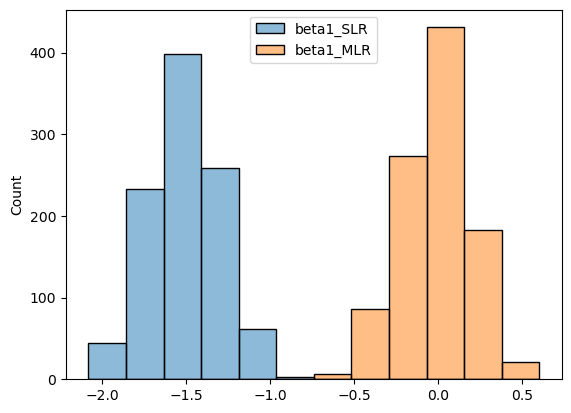

In [7]:
import seaborn as sns
sns.histplot(results);